# 03 · Risk: how much do VaR models understate crash risk?

**Value at Risk (VaR)** at 99% is the loss a portfolio should exceed on only 1% of days. **Expected Shortfall (ES)** is the average loss on those worst 1% of days. Banks report both every day: VaR sets trading limits and, under Basel, capital, and the 2016 rules (FRTB) moved bank capital to ES because VaR says nothing about how bad the bad days are.

A VaR model makes a testable promise: losses beyond it on 1% of days, spread out over time. This study tests that promise for five models over 90 years of daily data, on two portfolios:
- **The US stock market** (value-weighted, total return).
- **Industry momentum**, the long-short strategy from study 02, whose worst month lost 58%.

| Model | Volatility | Tails | Used by |
|---|---|---|---|
| Normal | 500-day rolling | normal | textbook |
| Historical simulation | — (empirical quantile of last 500 days) | empirical | most banks |
| EWMA (RiskMetrics) | exponentially weighted, λ = 0.94 | normal | J.P. Morgan 1994 standard |
| Filtered historical (FHS) | EWMA | empirical, of volatility-scaled returns | many banks |
| GARCH(1,1)-t | GARCH, re-estimated yearly on 10 years | Student t | academic standard |

Every forecast for day *t* uses data up to *t − 1* only (tested in `tests/test_risk.py`).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from quant_research.backtest import engine
from quant_research.data import french
from quant_research.risk import backtest as vb, garch, var
from quant_research.strategies import momentum as mom

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
pct = plt.FuncFormatter(lambda x, _: f"{x:.0%}")
MODELS = {"normal": "Normal", "historical": "Historical", "ewma": "EWMA", "fhs": "Filtered historical", "garch_t": "GARCH-t"}

ff_d = french.load("ff3_daily")
ind_d, ind, ff_m = french.load("ind49_daily"), french.load("ind49"), french.load("ff3")
market = (ff_d["Mkt-RF"] + ff_d["RF"]).rename("market")

# Industry momentum from study 02, held monthly, valued daily
tradable = ind.where(ind.notna() | ind.ffill().isna(), 0.0)
w = mom.long_short(mom.trailing_return(ind, 12, 1), 0.2)
monthly = engine.run(w[w.index < ind.index.max()], tradable)
momentum = engine.daily_returns(monthly.held, ind_d).rename("momentum")
check = (1 + momentum).resample("ME").prod() - 1
print(f"Daily momentum compounds to the monthly backtest: correlation {check.corr(monthly.gross):.4f}")
series = {"Market": market, "Industry momentum": momentum}
print({k: f"{len(v):,} days, {v.index.min():%Y-%m-%d} to {v.index.max():%Y-%m-%d}" for k, v in series.items()})

Daily momentum compounds to the monthly backtest: correlation 0.9998
{'Market': '26,338 days, 1926-07-01 to 2026-09-30', 'Industry momentum': '26,039 days, 1927-07-01 to 2026-09-30'}


## 1 · How fat are the tails?

If daily returns were normal, a move of more than 5 standard deviations would happen about once every 14,000 years of trading.

,excess kurtosis,skew,worst day,worst day (sd),days beyond 5 sd,normal expects
Market,16.1249,-0.1659,-0.1741,-16.2093,101.0000,0.0151
Industry momentum,58.7947,-2.3190,-0.3013,-30.6602,88.0000,0.0149


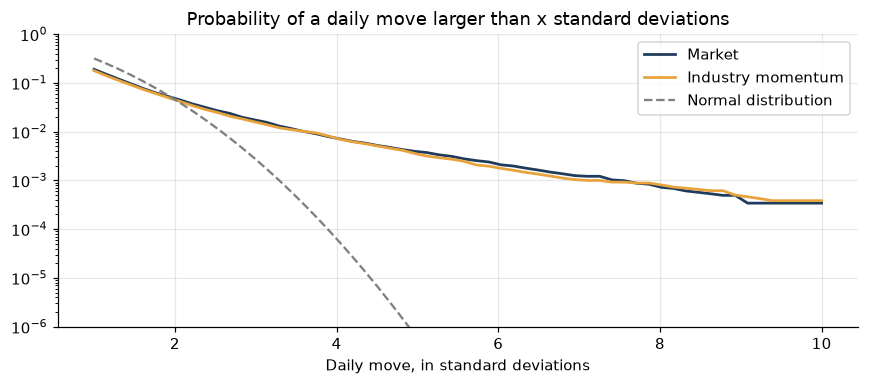

In [2]:
tails = {}
for name, r in series.items():
    z = (r - r.mean()) / r.std()
    tails[name] = {"excess kurtosis": stats.kurtosis(r), "skew": stats.skew(r), "worst day": r.min(),
                   "worst day (sd)": z.min(), "days beyond 5 sd": int((z.abs() > 5).sum()),
                   "normal expects": len(r) * 2 * stats.norm.sf(5)}
display(pd.DataFrame(tails).T)

fig, ax = plt.subplots(figsize=(8, 3.6))
grid = np.linspace(1, 10, 60)
for (name, r), c in zip(series.items(), ["#1f3b5c", "#e8a33d"]):
    z = ((r - r.mean()) / r.std()).abs()
    ax.semilogy(grid, [(z > g).mean() for g in grid], color=c, lw=1.8, label=name)
ax.semilogy(grid, 2 * stats.norm.sf(grid), color="grey", ls="--", label="Normal distribution")
ax.set_ylim(1e-6, 1)
ax.set_xlabel("Daily move, in standard deviations")
ax.set_title("Probability of a daily move larger than x standard deviations")
ax.legend()
plt.tight_layout()

Both series have about a hundred days beyond 5 standard deviations where the normal distribution expects almost none. Market tails are fat; momentum's are fatter (kurtosis near 60), as study 02's crash analysis suggested. At 3 standard deviations the normal curve is still in the right range; in the region a 99% VaR depends on, the gap opens fast.

## 2 · One-day 99% VaR: five models, 90 years

Each model forecasts VaR and ES for every day. The comparison starts once all models have enough history (GARCH needs ten years), i.e. from the mid-1930s: about 23,500 days and 235 expected exceptions per model.

**Reading the tests.**
- **Kupiec:** is the exception rate 1%? A p-value under 0.05 rejects.
- **Independence (Christoffersen):** are exceptions spread out, or does one predict the next? Clustered exceptions mean the model reacts too slowly.
- **Basel traffic light:** count of 250-day years with 5–9 exceptions (yellow) and 10 or more (red: the regulator rejects the model).
- **ES Z2 (Acerbi-Szekely):** 0 if Expected Shortfall is right. It adds up the losses on exception days relative to what the model's ES allows for, so it penalizes breaches that are too frequent *and* too large. A Z2 of 0.5 means tail losses totalled 50% more than the model allowed for.

In [3]:
forecasts, garch_fits, reports = {}, {}, {}
for name, r in series.items():
    f = var.forecasts(r, window=500)
    g, fits = garch.rolling_forecasts(r, window=2500, refit=250)
    forecasts[name], garch_fits[name] = f.join(g).dropna(), fits
    f = forecasts[name]
    reports[name] = pd.DataFrame({label: vb.report(r[f.index], f[f"var_{m}"], f[f"es_{m}"])
                                  for m, label in MODELS.items()}).T
for name, rep in reports.items():
    print(f"{name}: {rep['days'].iloc[0]:,.0f} days from {forecasts[name].index.min():%Y-%m}")
    display(rep.drop(columns=["days", "expected rate"]).style.format(
        {"exceptions": "{:.0f}", "rate": "{:.2%}", "Kupiec p": "{:.3f}", "independence p": "{:.3f}",
         "red years": "{:.0f}", "yellow years": "{:.0f}", "ES Z2": "{:+.2f}"}))

Market: 23,838 days from 1934-12


,exceptions,rate,Kupiec p,independence p,red years,yellow years,ES Z2
Normal,519,2.18%,0.000,0.000,19,26,+1.81
Historical,344,1.44%,0.000,0.000,10,24,+0.53
EWMA,507,2.13%,0.000,0.000,7,51,+1.57
Filtered historical,284,1.19%,0.004,0.003,0,15,+0.21
GARCH-t,326,1.37%,0.000,0.125,0,28,+0.38


Industry momentum: 23,539 days from 1935-12


,exceptions,rate,Kupiec p,independence p,red years,yellow years,ES Z2
Normal,526,2.23%,0.000,0.000,15,26,+1.73
Historical,342,1.45%,0.000,0.000,7,21,+0.54
EWMA,437,1.86%,0.000,0.000,0,48,+1.07
Filtered historical,282,1.20%,0.003,0.001,0,10,+0.21
GARCH-t,299,1.27%,0.000,0.001,1,20,+0.31


**What the table shows.**
- **Normal VaR fails worst.** It is breached on 2.2% of days instead of 1%, with 15–19 red years. A Z2 of about 1.8 means tail losses totalled nearly three times what its ES allowed for: twice as many breaches, each a little larger than expected.
- **Historical simulation**, the most common bank method, is better on average but its exceptions cluster: 500 days of history are slow to notice a crisis, so the misses arrive in runs. It still has 7–10 red years.
- **EWMA fixes the speed but not the tails:** it reacts to volatility, so there are few red years, but its normal tails still give about 2% exceptions.
- **Filtered historical simulation (FHS) is the best of the five:** fast volatility plus empirical tails gives 1.2% exceptions, no red years, and the smallest ES error.
- **GARCH-t** is close behind, and for the market it is the only model whose exceptions are independent.

**No model passes the Kupiec test.** With 23,000 days the test can detect a 1.2% rate against a 1% target. Every model underestimates the tail a little, even the good ones. The practical question is by how much, and the answer splits the models clearly.

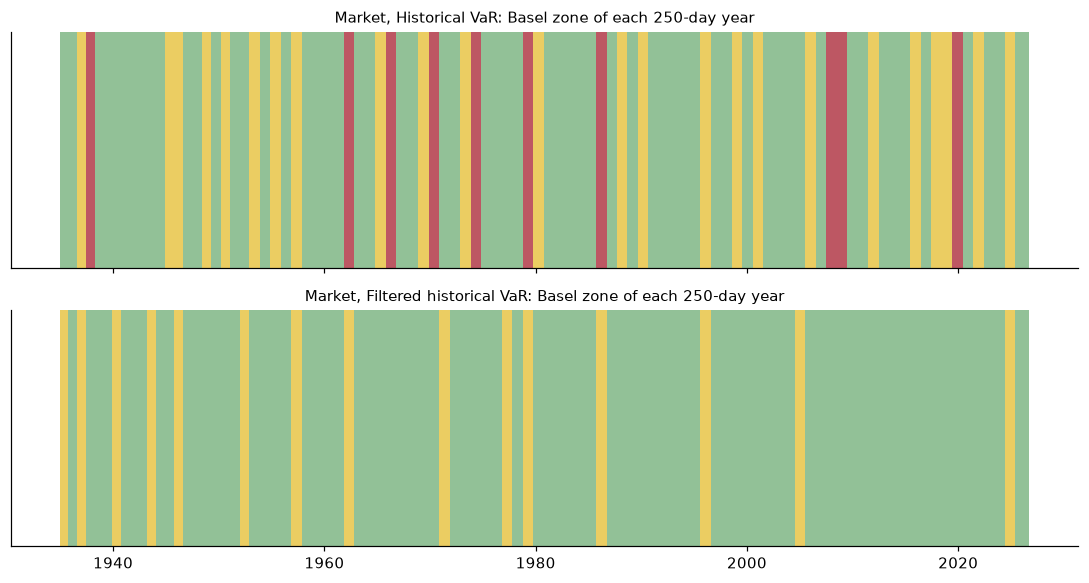

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True)
zone_colors = {"green": "#7fb685", "yellow": "#e8c547", "red": "#b23a48"}
r, f = market, forecasts["Market"]
for ax, m in zip(axes, ("historical", "fhs")):
    zones = vb.basel_zones(vb.exceptions(r[f.index], f[f"var_{m}"]))
    ends = list(zones.index[1:]) + [f.index.max()]
    for (d, z), e in zip(zones.items(), ends):
        ax.axvspan(d, e, color=zone_colors[z], alpha=0.85, lw=0)
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(f"Market, {MODELS[m]} VaR: Basel zone of each 250-day year", fontsize=10)
plt.tight_layout()

## 3 · In a crisis

The real test of a risk model is the few weeks that matter. Three episodes: the 1987 crash (−17% in a day for the value-weighted market), the March 2020 COVID crash, and momentum's spring 2009 crash.

In [5]:
episodes = [("Market", "1987-10-01", "1987-10-31", "October 1987"), ("Market", "2020-02-20", "2020-03-31", "COVID, 2020"),
            ("Industry momentum", "2009-03-01", "2009-05-31", "Momentum crash, 2009")]
rows = {}
for name, a, b, label in episodes:
    r, f = series[name][a:b], forecasts[name].loc[a:b]
    worst = r.idxmin()
    row = {"worst day": f"{worst:%Y-%m-%d}", "loss": -r.min()}
    row.update({f"VaR {MODELS[m]}": f.at[worst, f"var_{m}"] for m in ("normal", "historical", "fhs", "garch_t")})
    row.update({f"exceptions {MODELS[m]}": int(vb.exceptions(r, f[f"var_{m}"]).sum()) for m in MODELS})
    rows[label] = row
crisis = pd.DataFrame(rows).T
crisis

,worst day,loss,VaR Normal,VaR Historical,VaR Filtered historical,VaR GARCH-t,exceptions Normal,exceptions Historical,exceptions EWMA,exceptions Filtered historical,exceptions GARCH-t
October 1987,1987-10-19,0.1741,0.0191,0.0225,0.0520,0.0374,7,6,4,2,4
"COVID, 2020",2020-03-16,0.1200,0.0293,0.0338,0.1457,0.1526,11,9,6,3,2
"Momentum crash, 2009",2009-04-09,0.1015,0.0444,0.0523,0.0893,0.0864,8,7,3,2,2


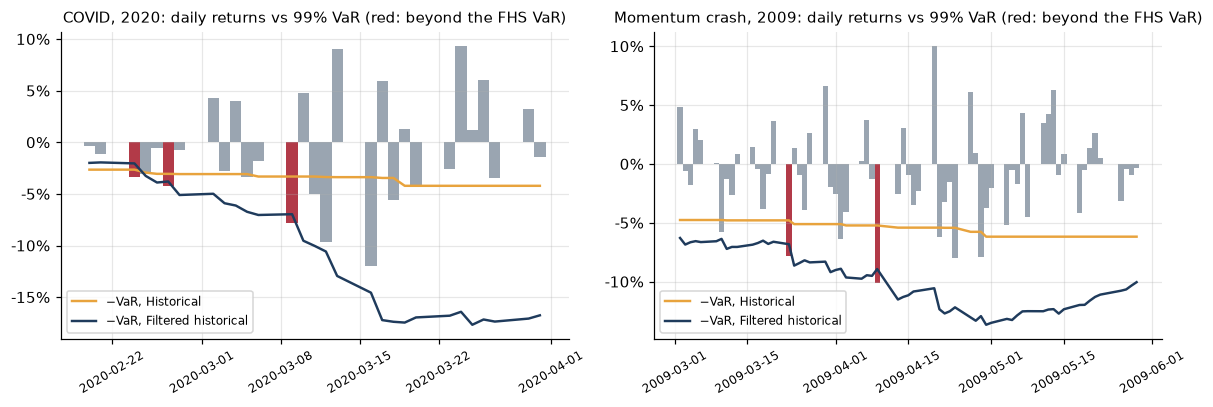

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, a, b, label) in zip(axes, [episodes[1], episodes[2]]):
    r, f = series[name][a:b], forecasts[name].loc[a:b]
    ax.bar(r.index, r, color=np.where(r < -f["var_fhs"], "#b23a48", "#9aa5b1"), width=1.0)
    for m, c in (("historical", "#e8a33d"), ("fhs", "#1f3b5c")):
        ax.plot(f.index, -f[f"var_{m}"], color=c, lw=1.6, label=f"−VaR, {MODELS[m]}")
    ax.yaxis.set_major_formatter(pct)
    ax.set_title(f"{label}: daily returns vs 99% VaR (red: beyond the FHS VaR)", fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()

- **Nothing predicts the first day.** On 19 October 1987 the best model's VaR was about 5%, against a 17% loss. Every daily model is a forecast of tomorrow from yesterday, and a jump from calm is invisible to all of them.
- **What differs is the following days.** Historical VaR barely moved during March 2020 and was breached day after day. FHS and GARCH raised VaR within days and were breached two or three times instead of nine to eleven.
- **Momentum's 2009 crash looks the same.** It came with exploding volatility, which volatility-scaled models caught.

## 4 · Ten-day VaR and Monte Carlo

Basel's VaR horizon is 10 days, usually computed as √10 × the 1-day VaR. That rule is exact only for independent, normal returns. Two things work against it, in opposite directions:
- **Adding up days thins the tails**, because sums of fat-tailed returns look more normal (the central limit theorem), so √10 × a fat-tailed 1-day VaR overstates.
- **Volatility clustering fattens multi-day tails**, because a bad day raises the volatility of the next ones, so √10 understates.

Monte Carlo handles both: simulate 5,000 ten-day paths from the fitted GARCH-t, with volatility updating along each path, and read off the 1% quantile (`risk/garch.py: simulate_losses`). The test uses non-overlapping 10-day blocks, about 2,400 per series, so about 24 exceptions are expected.

In [7]:
H = 10
ten_day = {}
for name, r in series.items():
    f, fits = forecasts[name], garch_fits[name]
    hist10 = (1 + r).rolling(H).apply(np.prod, raw=True) - 1
    rows = []
    for k, i in enumerate(range(r.index.get_loc(f.index[0]), len(r) - H, H)):
        d = r.index[i]
        par = fits[fits.index <= d].iloc[-1]
        sigma2 = f.at[d, "sigma"] ** 2
        fitted = garch.GarchParams(par.mu, par.omega, par.alpha, par.beta, par.nu)
        zero_mean = garch.GarchParams(0.0, par.omega, par.alpha, par.beta, par.nu)
        rows.append({"date": d, "realized": (1 + r.iloc[i:i + H]).prod() - 1,
                     "√10 × normal": np.sqrt(H) * f.at[d, "var_normal"],
                     "√10 × FHS": np.sqrt(H) * f.at[d, "var_fhs"],
                     "√10 × GARCH-t": np.sqrt(H) * f.at[d, "var_garch_t"],
                     "Historical 10-day": -np.quantile(hist10.iloc[max(0, i - 2500):i].dropna(), 0.01),
                     "Monte Carlo GARCH-t, fitted mean": -np.quantile(garch.simulate_losses(fitted, sigma2, H, 5000, seed=k), 0.01),
                     "Monte Carlo GARCH-t, zero mean": -np.quantile(garch.simulate_losses(zero_mean, sigma2, H, 5000, seed=k), 0.01)})
    ten_day[name] = pd.DataFrame(rows).set_index("date")

for name, res in ten_day.items():
    rep = pd.DataFrame({m: vb.report(res["realized"], res[m]) for m in res.columns[1:]}).T
    rep["median VaR"] = res.iloc[:, 1:].median()
    print(f"{name}: {len(res):,} ten-day blocks")
    display(rep[["exceptions", "rate", "Kupiec p", "independence p", "median VaR"]].style.format(
        {"exceptions": "{:.0f}", "rate": "{:.2%}", "Kupiec p": "{:.3f}", "independence p": "{:.3f}", "median VaR": "{:.1%}"}))

Market: 2,383 ten-day blocks


,exceptions,rate,Kupiec p,independence p,median VaR
√10 × normal,57,2.39%,0.000,0.058,5.9%
√10 × FHS,36,1.51%,0.020,0.293,6.4%
√10 × GARCH-t,38,1.59%,0.007,0.267,5.8%
Historical 10-day,28,1.17%,0.403,0.043,8.1%
"Monte Carlo GARCH-t, fitted mean",54,2.27%,0.000,0.113,5.2%
"Monte Carlo GARCH-t, zero mean",33,1.38%,0.074,0.336,6.0%


Industry momentum: 2,353 ten-day blocks


,exceptions,rate,Kupiec p,independence p,median VaR
√10 × normal,64,2.72%,0.000,0.129,4.7%
√10 × FHS,43,1.83%,0.000,0.206,5.0%
√10 × GARCH-t,48,2.04%,0.000,0.157,4.8%
Historical 10-day,28,1.19%,0.369,0.044,7.8%
"Monte Carlo GARCH-t, fitted mean",62,2.63%,0.000,0.584,4.4%
"Monte Carlo GARCH-t, zero mean",50,2.12%,0.000,0.141,4.8%


**The first Monte Carlo run did worse than the simple √10 rule.** The model wasn't wrong; one of its inputs was:

In [8]:
pd.DataFrame({name: {"actual mean daily return": series[name].mean(), "median daily return": series[name].median(),
                     "GARCH-t fitted mean (average of refits)": garch_fits[name]["mu"].mean()}
              for name in series}).style.format("{:.4%}")

,Market,Industry momentum
actual mean daily return,0.0430%,0.0285%
median daily return,0.0800%,0.0553%
GARCH-t fitted mean (average of refits),0.0815%,0.0479%


With fat-tailed (t) errors, maximum likelihood estimates the "mean" close to the **median** day, because it down-weights extreme observations. For a negatively skewed series the median is well above the mean: for the market, 0.08% a day against an actual 0.04%. Over one day that is invisible; compounded over 10 days in the simulation it takes about 0.8 percentage points off every VaR. Setting the expected return to zero, the usual conservative convention in risk management, fixes it for the market: Monte Carlo then has 1.4% exceptions and is the only 10-day method that passes both tests. (Historical 10-day VaR has the right rate, but its misses cluster, and it is the most conservative model by far, with a median VaR of 8%.)

**For momentum it doesn't.** Even with zero drift, Monte Carlo GARCH is breached on 2.1% of 10-day periods. Its multi-day crashes come from the market-rebound exposure found in study 02: a run of up days for the market is a run of losses for the strategy. A volatility model has no way to see that; section 5 comes back to it.

**Which regime do the misses come from?**

In [9]:
res, f = ten_day["Market"], forecasts["Market"]
regime = pd.qcut(f.loc[res.index, "sigma"], 4, labels=["calm", "quartile 2", "quartile 3", "turbulent"])
pd.DataFrame({m: vb.exceptions(res["realized"], res[m]).groupby(regime, observed=True).mean()
              for m in ("Historical 10-day", "√10 × GARCH-t", "Monte Carlo GARCH-t, zero mean")}).style.format("{:.2%}")

,Historical 10-day,√10 × GARCH-t,"Monte Carlo GARCH-t, zero mean"
sigma,,,
calm,0.67%,2.18%,1.85%
quartile 2,0.67%,1.68%,1.51%
quartile 3,0.84%,1.68%,1.34%
turbulent,2.52%,0.84%,0.84%


The models fail in opposite places:
- **Volatility models miss in calm markets.** When recent volatility is low they forecast low risk, and the shocks that end calm periods (1987, February 2020) come from there.
- **Historical simulation misses in turbulent markets.** Its 10 years of history include past crises, so it is conservative in calm times but slow when a new crisis starts.

That is an argument for combining them. Basel's stressed VaR does something similar: it adds a VaR computed on a historical crisis period to the current one.

## 5 · Does momentum's crash state show up?

Study 02 found momentum crashes when the market rebounds after a bear market. If a risk model already captures this through volatility, its exceptions should be no more frequent in that state.

In [10]:
r, f = momentum, forecasts["Industry momentum"]
prior = (1 + ff_m["Mkt-RF"]).rolling(24).apply(np.prod, raw=True).shift(1) - 1
bear = (prior < 0).reindex(pd.date_range(ff_m.index.min(), r.index.max(), freq="D")).bfill().reindex(f.index)
state = bear.map({True: "after a bear market", False: "normal"}).rename("state")
pd.DataFrame({MODELS[m]: vb.exceptions(r[f.index], f[f"var_{m}"]).groupby(state).mean()
              for m in ("historical", "fhs", "garch_t")}).T.assign(
    days_in_bear_state=int(bear.sum())).style.format({"after a bear market": "{:.2%}", "normal": "{:.2%}",
                                                       "days_in_bear_state": "{:,.0f}"})

state,after a bear market,normal,days_in_bear_state
Historical,1.77%,1.36%,"5,145"
Filtered historical,1.26%,1.18%,"5,145"
GARCH-t,1.52%,1.20%,"5,145"


At the daily horizon, mostly yes. The momentum crashes came with rising volatility, so FHS's exception rate is only slightly higher after bear markets (1.26% against 1.18%). Historical simulation and GARCH-t do noticeably worse in that state. Over 10 days the same exposure produces the multi-day losses that no volatility model handled (section 4). That is the case for a scenario test alongside VaR: what does the strategy lose if the market rebounds 20% next month?

## Conclusions

| Question | Answer from 90 years of daily data |
|---|---|
| How fat are the tails? | About 100 days beyond 5 standard deviations per series where a normal distribution expects almost none |
| Which 1-day model works? | **Filtered historical simulation**: 1.2% exceptions, no red Basel years, smallest ES error. GARCH-t is close |
| What fails? | Normal VaR (2.2% exceptions, tail losses nearly 3x what its ES allows for); historical simulation clusters its misses |
| Can any model predict a crash day? | No. 19 October 1987 was a 17% loss against a VaR of 5% or less. The good models recover within days |
| Ten-day horizon | √10 scaling is mediocre. For the market, **Monte Carlo GARCH-t works, but only with a zero expected return**: the t-likelihood's mean estimate behaves like the median and understates risk. For momentum no model is right, because its multi-day crashes come from market exposure, not volatility |
| Where do models miss? | Volatility models in calm periods, historical simulation in turbulent ones |

**For a risk team:** use FHS or GARCH-t for daily VaR. Simulate multi-day risk rather than scaling by √10, and set the drift to zero. Monitor clustering, not just exception counts. Pair VaR with scenarios for the risks it can't see, such as momentum's rebound exposure.